# Step 1.a — ET0 method: Hargreaves vs Jensen-Haise vs Oudin, validated against AgERA5

Test year **2000** only (daily, full year). All three ET0 formulas are computed on the raw ERA5 0.25deg daily
grid (`0_Input_data/ERA5 data`), then compared pixel by pixel to the AgERA5 "Reference Evapotranspiration"
product (Penman-Monteith FAO-56, 0.1deg, downloaded from CDS `sis-agrometeorological-indicators`), used here
as the benchmark because ERA5's own "potential evaporation" field is documented to be unreliable for this
purpose, while AgERA5 is a precomputed FAO-56 Penman-Monteith product (same source GAEZ v5 uses).

**Formulas**
- Hargreaves-Samani (current `1.a`): `ET0 = 0.0023 * Ra * (Tmean + 17.8) * sqrt(Tmax - Tmin)`, Ra = extraterrestrial
  radiation (geometric, not measured).
- Jensen-Haise (1963): `ET0 = (0.025 * Tmean + 0.08) * Rs`, Rs = **measured** solar radiation (ERA5 `dswrf`),
  expressed in mm/day (`Rs[MJ/m2/day] / 2.45`).
- **Oudin et al. (2005)**, added here per the user's question (2026-10-20): `ET0 = Ra_mm * (Tmean + 5) / 100`
  (0 if `Tmean + 5 <= 0`), where `Ra_mm = Ra / lambda` is the exact same Ra-to-mm/day conversion already used
  for Hargreaves in this notebook. Needs only Tmean and geometric Ra -- no Tmax-Tmin range, no measured
  radiation at all. Developed for large-scale rainfall-runoff hydrological modelling (streamflow simulation
  skill, not daily agronomic ET0 accuracy), so a priori it is not obvious it should do well here -- that is
  exactly what this test checks.

**Caveat**: one year only, and climate zones below are a crude latitude-band proxy (<=45N / 45-55N / >55N),
not a real Koppen classification. Good enough for a first read, not for a thesis-grade regional conclusion.

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, regionmask
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_DIR = cu.data_dir(CFG, "era5")  # data path: see 00_config_and_inventory.ipynb
AGERA5_DIR = cu.data_dir(CFG, "agera5_et0")  # data path: see 00_config_and_inventory.ipynb
OUT = BASE / "1_SVM" / "1_preprocessing_BIOvariables" / "outputs_ET0_method"
OUT.mkdir(parents=True, exist_ok=True)
YEAR = 2000
print("ERA5 dir:", ERA5_DIR, ERA5_DIR.exists())
print("AgERA5 dir:", AGERA5_DIR, AGERA5_DIR.exists(), "| files:", len(list(AGERA5_DIR.glob('*.nc'))))

C:\Users\elisa\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ERA5 dir: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\ERA5 data True
AgERA5 dir: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\0_Input_data\ERA5 data\AgERA5\Reference evapotranspiration True | files: 366


## 1. ERA5 0.25deg, year 2000 (tasmax, tasmin, dswrf)

In [2]:
def load_era5_year(var, year):
    ds = xr.open_dataset(cu.data_file(CFG, "era5", var))
    da = ds[var].sel(time=str(year)).load()
    ds.close()
    return da

tmax = load_era5_year("tasmax", YEAR)   # degC
tmin = load_era5_year("tasmin", YEAR)   # degC
sw_raw = load_era5_year("dswrf", YEAR)  # W/m2
sw_MJ = sw_raw * 0.0864                 # -> MJ/m2/day

lat = tmax.lat.values; lon = tmax.lon.values
dates = pd.DatetimeIndex(tmax.time.values)
doys = dates.dayofyear.values
print(f"ERA5 0.25deg grid: {len(lat)} x {len(lon)}, {len(dates)} days in {YEAR}")
print(f"lat {lat.min():.2f}..{lat.max():.2f}  lon {lon.min():.2f}..{lon.max():.2f}")

ERA5 0.25deg grid: 149 x 281, 366 days in 2000
lat 35.00..72.00  lon -25.00..45.00


## 2. Land mask (0.25deg, Natural Earth, pixel centre)

In [3]:
land_rg = regionmask.defined_regions.natural_earth_v5_0_0.land_10
land_mask = np.isfinite(land_rg.mask(lon, lat).values)   # (lat, lon)
print(f"land pixels: {int(land_mask.sum())} of {land_mask.size}")

land pixels: 19712 of 41869


## 3. Two ET0 formulas on the ERA5 0.25deg grid

In [4]:
def compute_Ra(lat_rad_2d, doy):
    Gsc = 0.0820
    dr = 1 + 0.033 * np.cos(2 * np.pi / 365 * doy)
    delta = 0.409 * np.sin(2 * np.pi / 365 * doy - 1.39)
    ws = np.arccos(np.clip(-np.tan(lat_rad_2d) * np.tan(delta), -1, 1))
    return (24 * 60 / np.pi) * Gsc * dr * (ws * np.sin(lat_rad_2d) * np.sin(delta)
                                            + np.cos(lat_rad_2d) * np.cos(delta) * np.sin(ws))

lat_rad_2d = np.radians(lat[:, None]) * np.ones((1, len(lon)))
TMAX = tmax.values; TMIN = tmin.values; SW = sw_MJ.values
Tmean = (TMAX + TMIN) / 2.0
TD = np.maximum(TMAX - TMIN, 0.0)

ETO_HG = np.full_like(TMAX, np.nan)   # Hargreaves-Samani, corrected Ra -> mm/d conversion
ETO_JH = np.full_like(TMAX, np.nan)   # Jensen-Haise (measured radiation)
ETO_OU = np.full_like(TMAX, np.nan)   # Oudin (2005) -- temperature + geometric Ra only
for t in range(len(dates)):
    Ra = compute_Ra(lat_rad_2d, doys[t])             # MJ/m2/day (geometric)
    lam = 2.501 - 0.002361 * Tmean[t]                # latent heat of vaporization (MJ/kg), temp-dependent (same as 2_GAEZ)
    Ra_mm = Ra / lam                                 # MJ/m2/day -> mm/day equivalent (the conversion missing in the original 1.a)
    ETO_HG[t] = 0.0023 * Ra_mm * (Tmean[t] + 17.8) * np.sqrt(TD[t])
    ETO_JH[t] = (0.025 * Tmean[t] + 0.08) * (SW[t] / 2.45)
    ETO_OU[t] = np.where(Tmean[t] + 5 > 0, Ra_mm * (Tmean[t] + 5) / 100.0, 0.0)
print("Hargreaves, Jensen-Haise and Oudin computed for", len(dates), "days.")
print(f"  mean ETO Hargreaves  : {np.nanmean(np.where(land_mask, ETO_HG, np.nan)):.2f} mm/d")
print(f"  mean ETO Jensen-Haise: {np.nanmean(np.where(land_mask, ETO_JH, np.nan)):.2f} mm/d")
print(f"  mean ETO Oudin       : {np.nanmean(np.where(land_mask, ETO_OU, np.nan)):.2f} mm/d")

Hargreaves, Jensen-Haise and Oudin computed for 366 days.


  mean ETO Hargreaves  : 1.95 mm/d


  mean ETO Jensen-Haise: 1.93 mm/d


  mean ETO Oudin       : 1.63 mm/d


## 4. AgERA5 reference ET0 (0.1deg) -> ERA5 0.25deg grid (bilinear)

In [5]:
files = sorted(AGERA5_DIR.glob(f"*{YEAR}*.nc"))
print(f"{len(files)} AgERA5 daily files for {YEAR}")

ref_chunks = []
ref_dates = []
for f in files:
    ds = xr.open_dataset(f)
    da = ds["ReferenceET_PenmanMonteith_FAO56"].isel(time=0)
    da = da.sortby("lat")                                            # ascending lat for interp
    da_i = da.interp(lat=lat, lon=lon, method="linear")
    ref_chunks.append(da_i.values.astype(np.float32))
    ref_dates.append(pd.Timestamp(ds.time.values[0]))
    ds.close()
order = np.argsort(ref_dates)
ETO_REF = np.stack(ref_chunks, axis=0)[order]
ref_dates = np.array(ref_dates)[order]
print("AgERA5 regridded to ERA5 0.25deg grid:", ETO_REF.shape)
assert (pd.DatetimeIndex(ref_dates) == dates).all(), "AgERA5 and ERA5 day sequences differ"
print(f"  mean ETO AgERA5 (reference): {np.nanmean(np.where(land_mask, ETO_REF, np.nan)):.2f} mm/d")

366 AgERA5 daily files for 2000


AgERA5 regridded to ERA5 0.25deg grid: (366, 149, 281)


  mean ETO AgERA5 (reference): 2.01 mm/d


## 5. Bias and RMSE vs AgERA5 (land pixels only)

In [6]:
def stats_vs_ref(method, name):
    diff = method - ETO_REF
    d = np.where(land_mask[None, :, :], diff, np.nan)
    bias = np.nanmean(d)
    rmse = np.sqrt(np.nanmean(d ** 2))
    print(f"{name:14s}: bias {bias:+.3f} mm/d | RMSE {rmse:.3f} mm/d")
    return d

diff_hg = stats_vs_ref(ETO_HG, "Hargreaves")
diff_jh = stats_vs_ref(ETO_JH, "Jensen-Haise")
diff_ou = stats_vs_ref(ETO_OU, "Oudin")

Hargreaves    : bias -0.060 mm/d | RMSE 0.560 mm/d


Jensen-Haise  : bias -0.084 mm/d | RMSE 0.690 mm/d


Oudin         : bias -0.381 mm/d | RMSE 0.779 mm/d


## 6. Bias by latitude band (crude climate-zone proxy)

<=45N approx. Mediterranean/southern Europe, 45-55N central Europe, >55N Scandinavia/northern Europe.
This is a latitude proxy, not a real climate classification -- stated as a limitation above.

In [7]:
bands = {"<=45N (south)": (lat <= 45), "45-55N (centre)": (lat > 45) & (lat <= 55), ">55N (north)": (lat > 55)}
rows = []
for label, m in bands.items():
    sel = land_mask & m[:, None]
    n = int(sel.sum())
    if n == 0:
        continue
    for name, d in [("Hargreaves", diff_hg), ("Jensen-Haise", diff_jh), ("Oudin", diff_ou)]:
        dd = d[:, sel]
        rows.append({"band": label, "method": name, "n_land_px": n,
                    "bias_mm_d": round(float(np.nanmean(dd)), 3),
                    "rmse_mm_d": round(float(np.sqrt(np.nanmean(dd ** 2))), 3)})
tab = pd.DataFrame(rows)
tab.to_csv(OUT / f"et0_bias_by_band_{YEAR}.csv", index=False)
print(tab.to_string(index=False))

           band       method  n_land_px  bias_mm_d  rmse_mm_d
  <=45N (south)   Hargreaves       5010     -0.214      0.765
  <=45N (south) Jensen-Haise       5010      0.249      0.947
  <=45N (south)        Oudin       5010     -0.712      1.089
45-55N (centre)   Hargreaves       7182     -0.014      0.495
45-55N (centre) Jensen-Haise       7182     -0.132      0.619
45-55N (centre)        Oudin       7182     -0.313      0.686
   >55N (north)   Hargreaves       7520     -0.003      0.445
   >55N (north) Jensen-Haise       7520     -0.260      0.534
   >55N (north)        Oudin       7520     -0.226      0.593


## 7. Maps: annual mean ET0 and annual mean bias

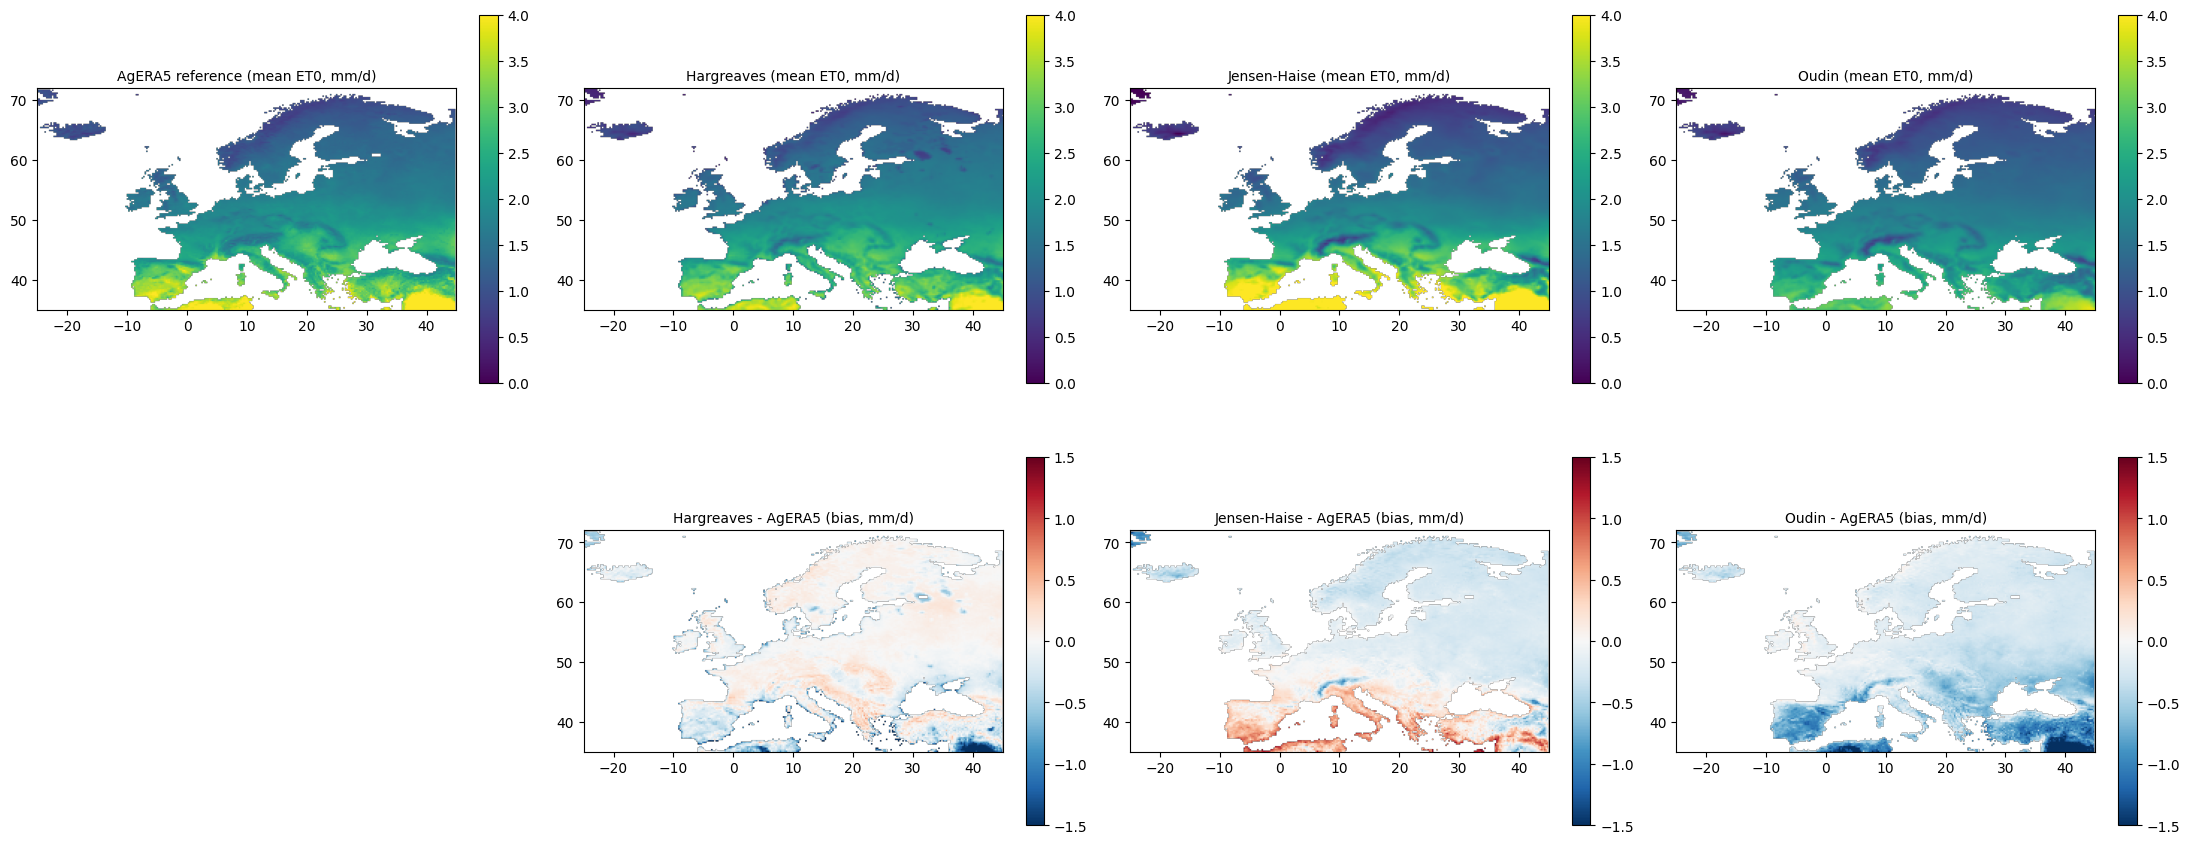

saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\1_preprocessing_BIOvariables\outputs_ET0_method\et0_maps_2000.png


In [8]:
ext = [lon.min(), lon.max(), lat.min(), lat.max()]
mean_hg = np.where(land_mask, np.nanmean(ETO_HG, axis=0), np.nan)
mean_jh = np.where(land_mask, np.nanmean(ETO_JH, axis=0), np.nan)
mean_ou = np.where(land_mask, np.nanmean(ETO_OU, axis=0), np.nan)
mean_ref = np.where(land_mask, np.nanmean(ETO_REF, axis=0), np.nan)
bias_hg = np.where(land_mask, np.nanmean(diff_hg, axis=0), np.nan)
bias_jh = np.where(land_mask, np.nanmean(diff_jh, axis=0), np.nan)
bias_ou = np.where(land_mask, np.nanmean(diff_ou, axis=0), np.nan)

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, d, t, cmap, vr in [
    (axes[0, 0], mean_ref, "AgERA5 reference (mean ET0, mm/d)", "viridis", (0, 4)),
    (axes[0, 1], mean_hg, "Hargreaves (mean ET0, mm/d)", "viridis", (0, 4)),
    (axes[0, 2], mean_jh, "Jensen-Haise (mean ET0, mm/d)", "viridis", (0, 4)),
    (axes[0, 3], mean_ou, "Oudin (mean ET0, mm/d)", "viridis", (0, 4)),
    (axes[1, 1], bias_hg, "Hargreaves - AgERA5 (bias, mm/d)", "RdBu_r", (-1.5, 1.5)),
    (axes[1, 2], bias_jh, "Jensen-Haise - AgERA5 (bias, mm/d)", "RdBu_r", (-1.5, 1.5)),
    (axes[1, 3], bias_ou, "Oudin - AgERA5 (bias, mm/d)", "RdBu_r", (-1.5, 1.5)),
]:
    im = ax.imshow(d, origin="lower", extent=ext, cmap=cmap, vmin=vr[0], vmax=vr[1])
    ax.set_title(t, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.04)
axes[1, 0].axis("off")
plt.tight_layout()
plt.savefig(OUT / f"et0_maps_{YEAR}.png", dpi=120)
plt.show()
print("saved:", OUT / f"et0_maps_{YEAR}.png")

## 8. Conclusion (printed, not asserted)

In [9]:
overall = pd.DataFrame([
    {"method": "Hargreaves", "bias_mm_d": round(float(np.nanmean(diff_hg)), 3), "rmse_mm_d": round(float(np.sqrt(np.nanmean(diff_hg**2))), 3)},
    {"method": "Jensen-Haise", "bias_mm_d": round(float(np.nanmean(diff_jh)), 3), "rmse_mm_d": round(float(np.sqrt(np.nanmean(diff_jh**2))), 3)},
    {"method": "Oudin", "bias_mm_d": round(float(np.nanmean(diff_ou)), 3), "rmse_mm_d": round(float(np.sqrt(np.nanmean(diff_ou**2))), 3)},
])
overall.to_csv(OUT / f"et0_overall_stats_{YEAR}.csv", index=False)
print(overall.to_string(index=False))
print()
print(tab.to_string(index=False))

      method  bias_mm_d  rmse_mm_d
  Hargreaves     -0.060      0.560
Jensen-Haise     -0.084      0.690
       Oudin     -0.381      0.779

           band       method  n_land_px  bias_mm_d  rmse_mm_d
  <=45N (south)   Hargreaves       5010     -0.214      0.765
  <=45N (south) Jensen-Haise       5010      0.249      0.947
  <=45N (south)        Oudin       5010     -0.712      1.089
45-55N (centre)   Hargreaves       7182     -0.014      0.495
45-55N (centre) Jensen-Haise       7182     -0.132      0.619
45-55N (centre)        Oudin       7182     -0.313      0.686
   >55N (north)   Hargreaves       7520     -0.003      0.445
   >55N (north) Jensen-Haise       7520     -0.260      0.534
   >55N (north)        Oudin       7520     -0.226      0.593
